In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as seaborn_module

# Configuramos estilo visual para los gráficos
seaborn_module.set_theme(style="darkgrid")
print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [ ]:

url_thingspeak = "https://api.thingspeak.com/channels/3525715/feeds.csv"

# Cargamos los datos en un DataFrame de Pandas
df = pd.read_csv(url_thingspeak)
# Mostramos las primeras filas para verificar la estructura
print(f"Total de registros descargados: {len(df)}")
df.head()

Total de registros descargados: 100


,created_at,entry_id,field1
0,2026-11-03 23:12:29 UTC,587,20
1,2026-11-03 23:12:45 UTC,588,52
2,2026-11-03 23:13:04 UTC,589,3
3,2026-11-03 23:13:20 UTC,590,3
4,2026-11-03 23:14:40 UTC,591,1


In [ ]:
df = df.rename(columns={'field1': 'nivel_ruido'})

df['created_at'] = pd.to_datetime(df['created_at'])
df['nivel_ruido'] = pd.to_numeric(df['nivel_ruido'], errors='coerce')
df = df.dropna(subset=['nivel_ruido'])

print("Datos limpios y listos para procesar.")

Datos limpios y listos para procesar.


In [ ]:
promedio = df['nivel_ruido'].mean()
maximo = df['nivel_ruido'].max()
minimo = df['nivel_ruido'].min()
desviacion = df['nivel_ruido'].std()

print("=== ESTADÍSTICAS DEL MONITOREO ACÚSTICO ===")
print(f"Promedio de ruido: {promedio:.2f} unidades")
print(f"Pico máximo registrado: {maximo} unidades")
print(f"Valor mínimo registrado: {minimo} unidades")
print(f"Desviación estándar: {desviacion:.2f}")

=== ESTADÍSTICAS DEL MONITOREO ACÚSTICO ===
Promedio de ruido: 13.56 unidades
Pico máximo registrado: 143 unidades
Valor mínimo registrado: 0 unidades
Desviación estándar: 22.04


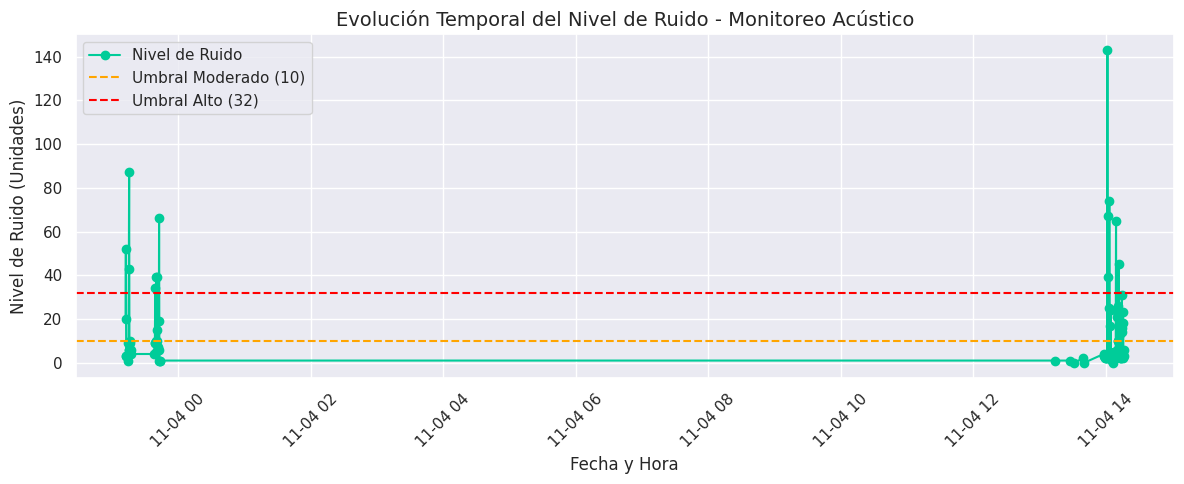

In [ ]:
plt.figure(figsize=(12, 5))

# Gráfico de evolución temporal del ruido
plt.plot(df['created_at'], df['nivel_ruido'], marker='o', linestyle='-', color='#00cc99', label='Nivel de Ruido')
plt.axhline(10, color='orange', linestyle='--', label='Umbral Moderado (10)')
plt.axhline(32, color='red', linestyle='--', label='Umbral Alto (32)')

plt.title('Evolución Temporal del Nivel de Ruido - Monitoreo Acústico', fontsize=14)
plt.xlabel('Fecha y Hora', fontsize=12)
plt.ylabel('Nivel de Ruido (Unidades)', fontsize=12)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()


plt.show()

In [ ]:
# Anteriormente mostramos los  datos de los últimos 100 registros, en esta parte vamos a mostrar todos los datos cargados al canal para poder ver cambio del gráfico en su totalidad

url_thingspeak = "https://api.thingspeak.com/channels/3525715/feeds.csv?results=8000"

df = pd.read_csv(url_thingspeak)

print(f"Total de registros históricos descargados: {len(df)}")
df.head()

Total de registros históricos descargados: 686


,created_at,entry_id,field1
0,2026-10-25 23:38:15 UTC,1,103
1,2026-10-25 23:38:31 UTC,2,90
2,2026-10-25 23:38:46 UTC,3,102
3,2026-10-25 23:39:02 UTC,4,104
4,2026-10-25 23:43:38 UTC,5,105


In [ ]:
df = df.rename(columns={'field1': 'nivel_ruido'})
df['created_at'] = pd.to_datetime(df['created_at'])
df['nivel_ruido'] = pd.to_numeric(df['nivel_ruido'], errors='coerce')
df = df.dropna(subset=['nivel_ruido'])

print("Datos limpios y listos para procesar.")

Datos limpios y listos para procesar.


In [ ]:
promedio = df['nivel_ruido'].mean()
maximo = df['nivel_ruido'].max()
minimo = df['nivel_ruido'].min()
desviacion = df['nivel_ruido'].std()

print("=== ESTADÍSTICAS DEL MONITOREO ACÚSTICO ===")
print(f"Promedio de ruido: {promedio:.2f} unidades")
print(f"Pico máximo registrado: {maximo} unidades")
print(f"Valor mínimo registrado: {minimo} unidades")
print(f"Desviación estándar: {desviacion:.2f}")

=== ESTADÍSTICAS DEL MONITOREO ACÚSTICO ===
Promedio de ruido: 200.10 unidades
Pico máximo registrado: 1024 unidades
Valor mínimo registrado: 0 unidades
Desviación estándar: 181.14


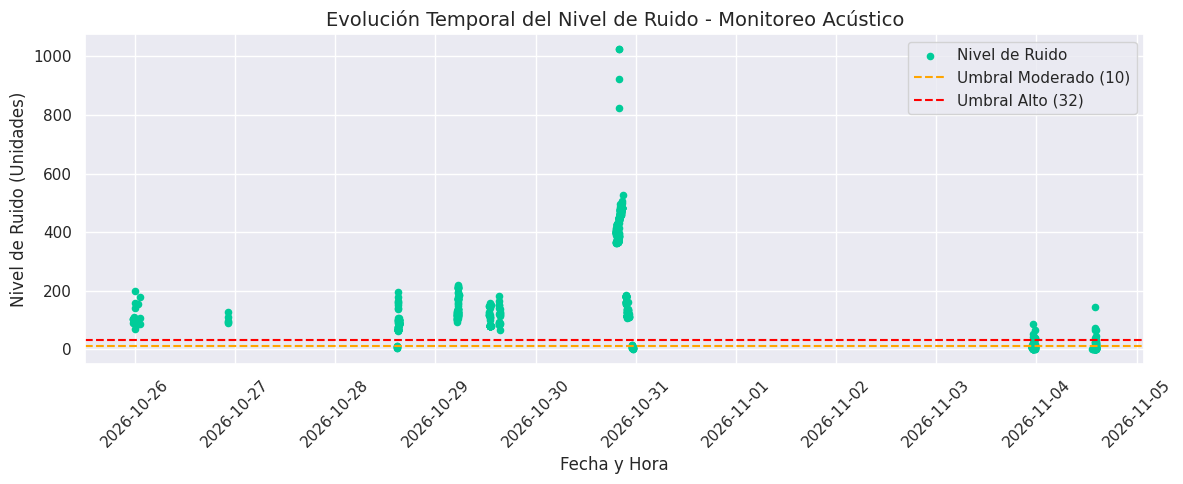

In [ ]:
plt.figure(figsize=(12, 5))

plt.scatter(df['created_at'], df['nivel_ruido'], color='#00cc99', label='Nivel de Ruido', s=20)

plt.axhline(10, color='orange', linestyle='--', label='Umbral Moderado (10)')
plt.axhline(32, color='red', linestyle='--', label='Umbral Alto (32)')

plt.title('Evolución Temporal del Nivel de Ruido - Monitoreo Acústico', fontsize=14)
plt.xlabel('Fecha y Hora', fontsize=12)
plt.ylabel('Nivel de Ruido (Unidades)', fontsize=12)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

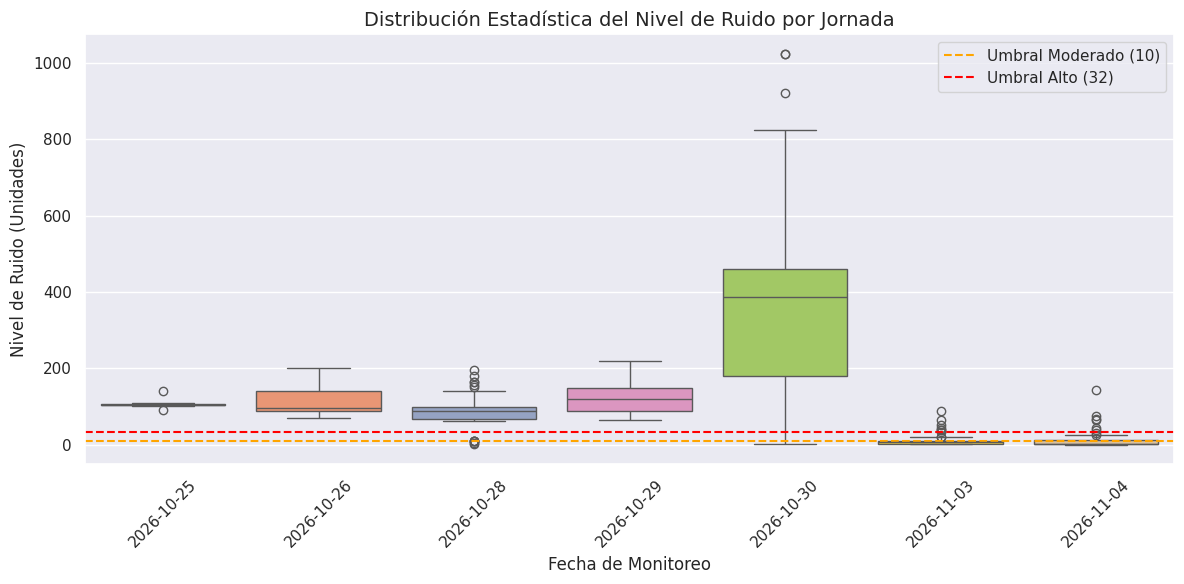

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df['fecha'] = df['created_at'].dt.date

plt.figure(figsize=(12, 6))
# Generamos un boxplot agrupado por día
sns.boxplot(x='fecha', y='nivel_ruido', data=df, palette='Set2', hue='fecha', legend=False)

plt.axhline(10, color='orange', linestyle='--', label='Umbral Moderado (10)')
plt.axhline(32, color='red', linestyle='--', label='Umbral Alto (32)')

plt.title('Distribución Estadística del Nivel de Ruido por Jornada', fontsize=14)
plt.xlabel('Fecha de Monitoreo', fontsize=12)
plt.ylabel('Nivel de Ruido (Unidades)', fontsize=12)
plt.legend(loc='upper right')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()